# Delivery TAT Analysis: where and why do orders run late?

**Business problem:** In quick commerce, customers expect fast, predictable delivery. Operations teams must track Delivery TAT (turnaround time), find the causes of slow or late orders, and flag bad trends early.

**Questions**
1. What do TAT and the late-order rate look like overall?
2. Which factors drive TAT: traffic, weather, area, vehicle, category, time of day, distance, agent?
3. Which factors are statistically significant, and how many minutes does each add?
4. Which segments produce most of the late orders?
5. What is a late-order reduction worth, under stated assumptions?

**Data:** a public India-based delivery dataset (Kaggle, "Amazon Delivery Dataset", about 43,000 orders). Save it as `data/amazon_delivery.csv`.
The dataset has **no cost field**, so cost-per-shipment is not measured here; section 12 uses clearly labelled assumptions. Median delivery time here is about 2 hours, so this behaves like general e-commerce delivery, not 10-minute quick commerce; the late threshold is set accordingly.

## 1. Setup

In [53]:
import sys, sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy import stats
sys.path.insert(0, ".")
from pipeline import load_raw, clean

sns.set_theme(style="whitegrid", palette="deep")
Path("outputs").mkdir(exist_ok=True)
ACCENT = "#b4571e"

DATA_PATH = "data/amazon_delivery.csv"   # change if your file name differs
SLA_MIN = 150                            # assumption: an order is "late" if it takes over 150 minutes (2.5 h)
if "DUMMY" in DATA_PATH:
    print("WARNING: this is synthetic test data. Do not report these results.")

def save(name):
    plt.tight_layout()
    plt.savefig(f"outputs/{name}.png", dpi=150, bbox_inches="tight")

## 2. Load, validate and clean (catch data errors first)

In [54]:
raw = load_raw(DATA_PATH)
df, dq = clean(raw)
df["late"] = df["Delivery_Time"] > SLA_MIN
print(f"Raw rows: {len(raw):,} | Clean rows: {len(df):,}")
pd.Series(dq, name="count").rename_axis("check").to_frame()

Raw rows: 43,739 | Clean rows: 40,046


,count
check,
raw_rows,43739
duplicate_order_ids_removed,0
missing_traffic,91
missing_weather,91
missing_agent_rating,54
missing_order_time,0
agent_rating_above_5_set_missing,53
agent_age_under_18_set_missing,38
invalid_date_removed,0


**Data issues found and fixed:**
- **3,693 orders (8.4%)** had a zero or invalid store coordinate and were removed. Bias check above: their average TAT (122.9 min) and grocery share (6.6%) match the kept rows (125.1 min, 6.1%), so removing them does not distort the results.
- **53 agent ratings above 5** and **38 agent ages under 18** are impossible and were set to missing; 54 ratings were already missing.
- **91 orders** had the text "NaN" for traffic and weather; they are labelled Unknown. "Metropolitian" (source spelling error) was corrected.
- **11 calendar days have no orders** (19 to 28 Feb and 22 Mar), so weekly and daily trends have a gap.
- No duplicate order IDs, no invalid dates or delivery times, and no distance over 50 km.

In [55]:
raw_ = raw.copy(); raw_["Category"] = raw_["Category"].astype(str).str.strip()
dropped = raw_[~raw_["Order_ID"].isin(set(df["Order_ID"]))]
pd.DataFrame({"kept": [len(df), df["Delivery_Time"].mean(), (df["Category"] == "Grocery").mean() * 100],
              "dropped": [len(dropped), dropped["Delivery_Time"].mean(), (dropped["Category"] == "Grocery").mean() * 100]},
             index=["orders", "avg TAT (min)", "% grocery"]).round(1)

,kept,dropped
orders,40046.0,3693.0
avg TAT (min),125.1,122.9
% grocery,6.1,6.6


**Bias check:** dropping rows with invalid coordinates is safe only if the dropped rows look like the kept ones. Compare average TAT and category mix above.

## 3. Headline KPIs

In [56]:
tat = df["Delivery_Time"]
kpi = {"Orders": len(df), "Avg TAT (min)": tat.mean(), "Median TAT (min)": tat.median(),
       "P90 TAT (min)": np.percentile(tat, 90), "P95 TAT (min)": np.percentile(tat, 95),
       "Avg distance (km)": df["distance_km"].mean()}
for s in (120, 150, 180):
    kpi[f"% over {s} min"] = (tat > s).mean() * 100
pd.Series(kpi).round(1).to_frame("value")

,value
Orders,40046.0
Avg TAT (min),125.1
Median TAT (min),125.0
P90 TAT (min),195.0
P95 TAT (min),215.0
Avg distance (km),9.7
% over 120 min,51.4
% over 150 min,28.0
% over 180 min,14.7


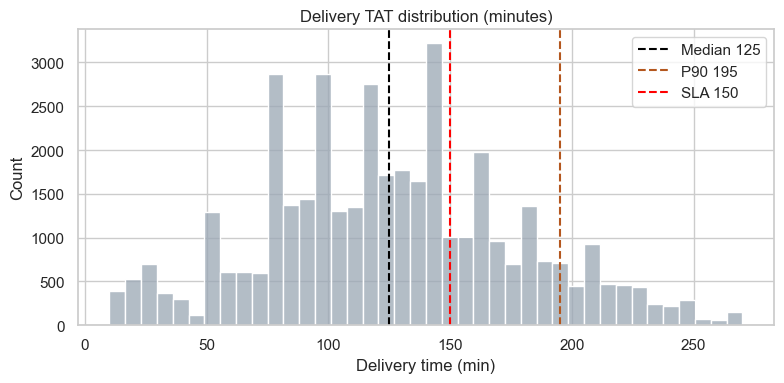

In [57]:
plt.figure(figsize=(8, 4))
sns.histplot(tat, bins=40, color="#9aa7b4")
for v, lab, col in [(tat.median(), "Median", "black"), (np.percentile(tat, 90), "P90", ACCENT), (SLA_MIN, "SLA", "red")]:
    plt.axvline(v, ls="--", color=col, label=f"{lab} {v:.0f}")
plt.legend(); plt.title("Delivery TAT distribution (minutes)"); plt.xlabel("Delivery time (min)")
save("00_tat_distribution"); plt.show()

## 4. TAT by operating conditions

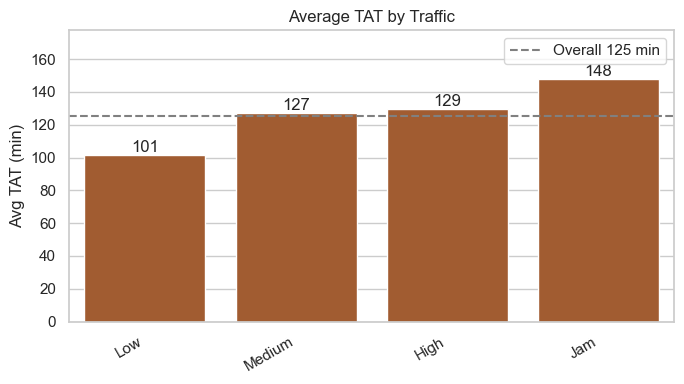

,Traffic,orders,avg_tat,p90_tat,pct_late
0,Low,13699,101.5,145.0,7.6
1,Medium,9755,127.0,190.0,30.5
2,High,3933,129.5,185.0,31.3
3,Jam,12610,148.0,220.0,47.4


In [58]:
def tat_by(col, order=None, title=None):
    t = (df.groupby(col).agg(orders=("Order_ID", "count"), avg_tat=("Delivery_Time", "mean"),
                             p90_tat=("Delivery_Time", lambda s: np.percentile(s, 90)),
                             pct_late=("late", "mean")).reset_index())
    t["pct_late"] = t["pct_late"] * 100
    t = t.sort_values("avg_tat", ascending=False) if order is None else t.set_index(col).reindex(
        [o for o in order if o in set(t[col])]).reset_index()
    plt.figure(figsize=(7, 4))
    ax = sns.barplot(data=t, x=col, y="avg_tat", color=ACCENT)
    ax.axhline(tat.mean(), ls="--", color="gray", label=f"Overall {tat.mean():.0f} min")
    for i, r in enumerate(t.itertuples()):
        ax.text(i, r.avg_tat, f"{r.avg_tat:.0f}", ha="center", va="bottom")
    ax.set_title(title or f"Average TAT by {col}"); ax.set_ylabel("Avg TAT (min)"); ax.set_xlabel("")
    ax.set_ylim(0, t["avg_tat"].max() * 1.2); ax.legend(loc="upper right")
    plt.xticks(rotation=30, ha="right"); save(f"tat_by_{col}"); plt.show()
    return t.round(1)

tat_by("Traffic", ["Low", "Medium", "High", "Jam"])

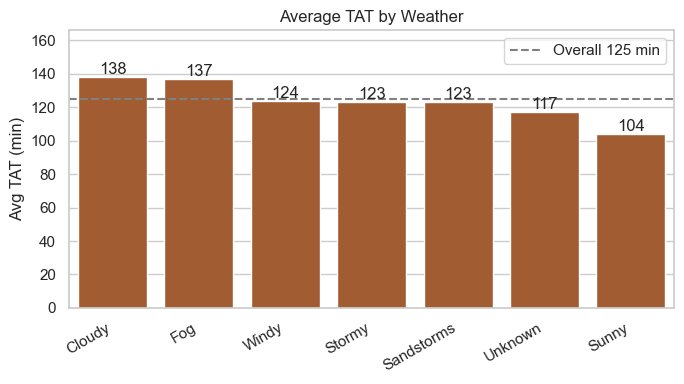

,Weather,orders,avg_tat,p90_tat,pct_late
0,Cloudy,6676,138.3,210.0,41.5
1,Fog,6784,136.9,210.0,41.2
6,Windy,6624,124.0,185.0,24.7
3,Stormy,6757,123.4,185.0,24.3
2,Sandstorms,6652,123.3,185.0,24.3
5,Unknown,49,117.0,175.0,18.4
4,Sunny,6504,103.9,160.0,11.6


In [59]:
tat_by("Weather")

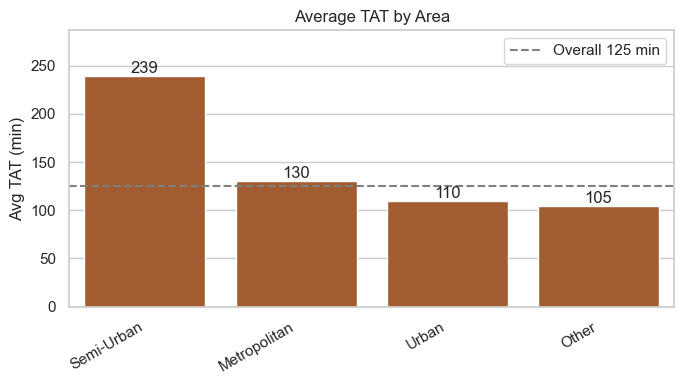

,Area,orders,avg_tat,p90_tat,pct_late
2,Semi-Urban,138,238.7,270.0,94.9
0,Metropolitan,29986,129.9,200.0,31.3
3,Urban,8874,109.6,175.0,17.6
1,Other,1048,104.5,165.0,14.7


In [60]:
tat_by("Area")

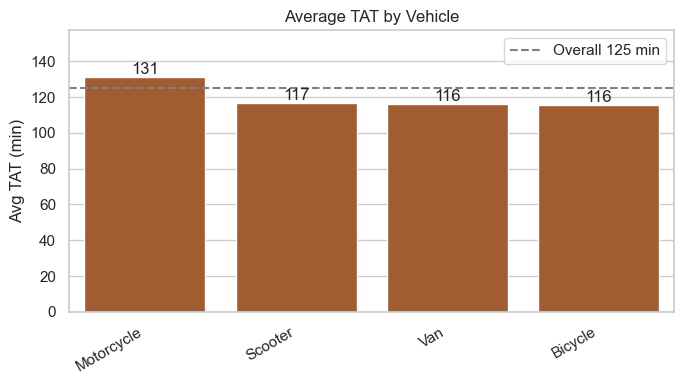

,Vehicle,orders,avg_tat,p90_tat,pct_late
1,Motorcycle,23464,131.1,205.0,31.7
2,Scooter,13374,116.6,185.0,23.0
3,Van,3200,116.2,185.0,22.0
0,Bicycle,8,115.6,156.5,12.5


In [61]:
tat_by("Vehicle")

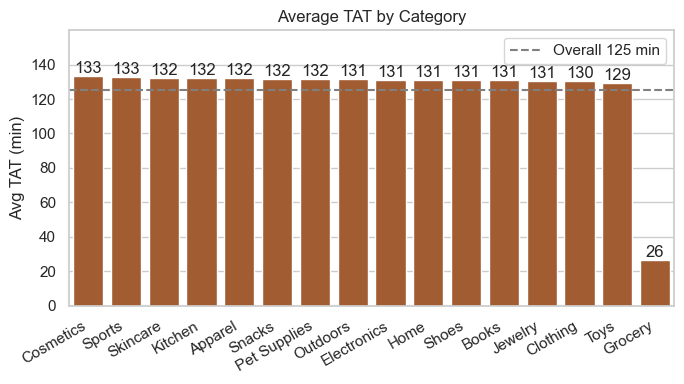

,Category,orders,avg_tat,p90_tat,pct_late
3,Cosmetics,2452,133.2,200.0,31.7
14,Sports,2476,132.5,195.0,30.8
12,Skincare,2556,132.4,200.0,30.6
8,Kitchen,2443,132.2,195.0,31.3
0,Apparel,2497,132.1,200.0,29.7
13,Snacks,2513,131.9,200.0,30.0
10,Pet Supplies,2461,131.9,195.0,30.2
9,Outdoors,2534,131.4,200.0,29.1
4,Electronics,2616,131.2,195.0,30.1
6,Home,2473,131.2,200.0,29.6


In [62]:
tat_by("Category")

**What stands out:**
- **Traffic:** Low 101.5 min vs Jam 148.0 min (+46 min); 47% of Jam orders run over 150 min vs 8% in Low traffic.
- **Weather:** Sunny is fastest (104 min); Cloudy (138) and Fog (137) are slowest, ahead of Stormy, Sandstorms and Windy (about 123).
- **Area:** Metropolitan is 130 min, Urban 110 min. Semi-Urban averages 239 min with 95% late, but only 138 orders (0.3%).
- **Vehicle:** motorcycles average 131 min vs about 116 for scooters and vans.
- **Category:** apart from Grocery, categories are nearly identical (129 to 133 min), so category is not a driver on its own.

### Grocery vs all other categories

In [63]:
df["segment"] = np.where(df["Category"] == "Grocery", "Grocery", "All other categories")
lens = df.groupby("segment").agg(orders=("Order_ID", "count"), avg_tat=("Delivery_Time", "mean"),
        p90_tat=("Delivery_Time", lambda s: np.percentile(s, 90)), avg_distance_km=("distance_km", "mean"),
        pct_over_45=("Delivery_Time", lambda s: (s > 45).mean() * 100),
        pct_over_150=("Delivery_Time", lambda s: (s > 150).mean() * 100)).round(1)
lens

,orders,avg_tat,p90_tat,avg_distance_km,pct_over_45,pct_over_150
segment,,,,,,
All other categories,37599,131.5,200.0,9.7,100.0,29.9
Grocery,2447,26.5,40.0,9.6,3.5,0.0


In [64]:
df.pivot_table(index="Traffic", columns="segment", values="Delivery_Time", aggfunc="mean") \
  .reindex(["Low", "Medium", "High", "Jam"]).round(1)

segment,All other categories,Grocery
Traffic,,
Low,106.5,21.2
Medium,133.6,27.2
High,135.9,27.1
Jam,155.8,31.2


**Grocery follows a different, much faster flow** than every other category, at the same average distance. Mixing them hides both patterns, so keep this split in mind for every chart below.

## 5. Time patterns: hour of day and day of week

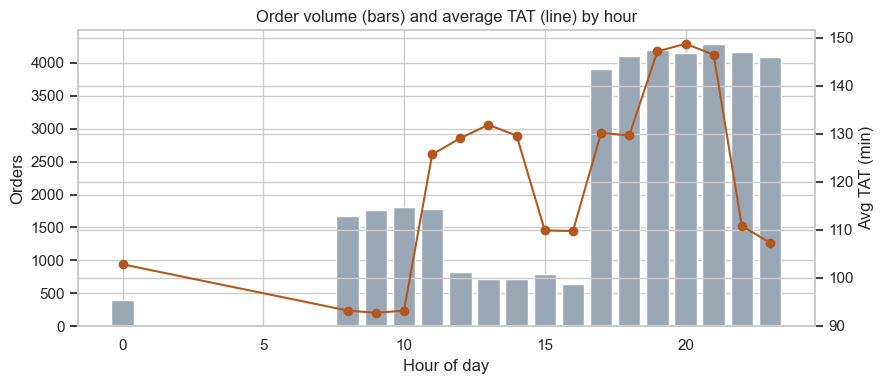

,hour,orders,avg_tat,pct_late
0,0,394,102.76,7.87
1,8,1667,93.12,2.64
2,9,1768,92.65,1.64
3,10,1809,93.11,2.16
4,11,1785,125.66,28.24
5,12,819,129.03,30.77
6,13,711,131.84,33.61
7,14,715,129.58,30.63
8,15,795,109.81,14.97
9,16,643,109.69,13.69


In [65]:
dh = df.dropna(subset=["hour"]).assign(hour=lambda d: d["hour"].astype(int),
                                       dow=lambda d: d["Order_Date"].dt.day_name())
by_hour = dh.groupby("hour").agg(orders=("Order_ID", "count"), avg_tat=("Delivery_Time", "mean"),
                                 pct_late=("late", "mean")).reset_index()
by_hour["pct_late"] = by_hour["pct_late"] * 100
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(by_hour["hour"], by_hour["orders"], color="#9aa7b4"); ax.set_ylabel("Orders"); ax.set_xlabel("Hour of day")
ax2 = ax.twinx(); ax2.plot(by_hour["hour"], by_hour["avg_tat"], color=ACCENT, marker="o"); ax2.set_ylabel("Avg TAT (min)")
ax.set_title("Order volume (bars) and average TAT (line) by hour"); save("01_by_hour"); plt.show()
by_hour.round(2)

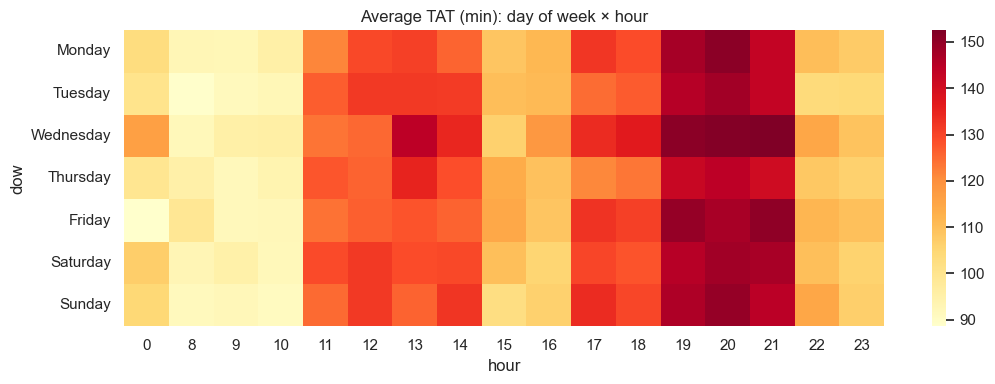

In [66]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
pv = dh.pivot_table(index="dow", columns="hour", values="Delivery_Time", aggfunc="mean").reindex(days)
plt.figure(figsize=(11, 4)); sns.heatmap(pv, cmap="YlOrRd", annot=False)
plt.title("Average TAT (min): day of week × hour"); save("02_heatmap_dow_hour"); plt.show()

**Time pattern:** orders arrive in two windows, 8 to 11 am and 5 pm to midnight. Morning is fastest (about 93 min, 2 to 3% late). **7 to 9 pm is the worst window** (about 147 min, 46 to 48% late), and TAT falls again after 10 pm (about 108 min).

## 6. Distance and agent factors

/Users/hp/Desktop/delivery_tat_analysis/.venv/lib/python3.9/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: divide by zero encountered in matmul
  return _core_matmul(x1, x2)
/Users/hp/Desktop/delivery_tat_analysis/.venv/lib/python3.9/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: overflow encountered in matmul
  return _core_matmul(x1, x2)
/Users/hp/Desktop/delivery_tat_analysis/.venv/lib/python3.9/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: invalid value encountered in matmul
  return _core_matmul(x1, x2)


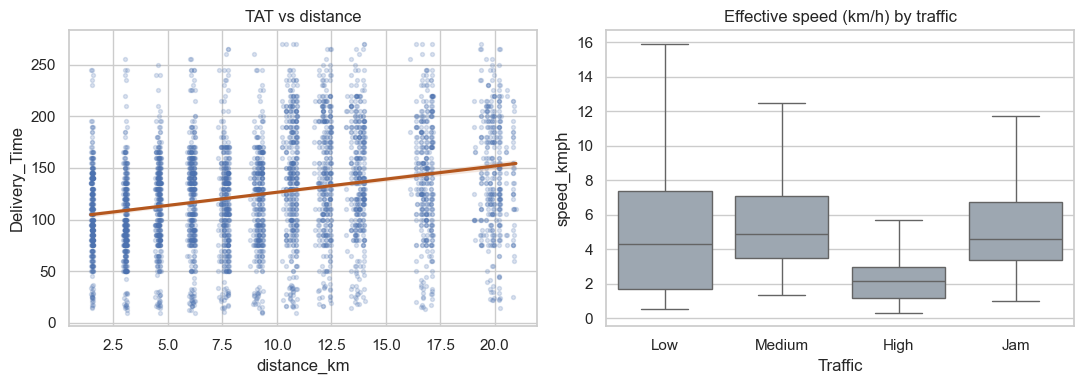

In [67]:
sample = df.sample(min(4000, len(df)), random_state=1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.regplot(data=sample, x="distance_km", y="Delivery_Time", scatter_kws={"alpha": .2, "s": 8},
            line_kws={"color": ACCENT}, ax=axes[0]); axes[0].set_title("TAT vs distance")
sns.boxplot(data=df, x="Traffic", y="speed_kmph", order=["Low", "Medium", "High", "Jam"],
            showfliers=False, color="#9aa7b4", ax=axes[1]); axes[1].set_title("Effective speed (km/h) by traffic")
save("03_distance_speed"); plt.show()

/var/folders/8s/b2jt_v9n3w33w2p74h42z43w0000gn/T/ipykernel_2666/3968531709.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  t = (df.groupby(col).agg(orders=("Order_ID", "count"), avg_tat=("Delivery_Time", "mean"),


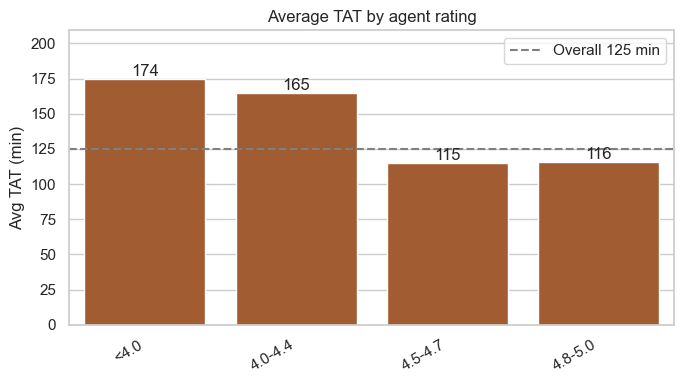

,RatingBand,orders,avg_tat,p90_tat,pct_late
0,<4.0,1253,174.4,215.0,91.4
1,4.0-4.4,6185,165.0,220.0,76.7
2,4.5-4.7,15906,115.4,175.0,15.4
3,4.8-5.0,16639,115.9,180.0,17.3


In [68]:
df["RatingBand"] = pd.cut(df["Agent_Rating"], [0, 3.9, 4.4, 4.7, 5.0], labels=["<4.0", "4.0-4.4", "4.5-4.7", "4.8-5.0"])
df["AgeBand"] = pd.cut(df["Agent_Age"], [0, 24, 29, 34, 100], labels=["<25", "25-29", "30-34", "35+"])
tat_by("RatingBand", ["<4.0", "4.0-4.4", "4.5-4.7", "4.8-5.0"], "Average TAT by agent rating")

/var/folders/8s/b2jt_v9n3w33w2p74h42z43w0000gn/T/ipykernel_2666/3968531709.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  t = (df.groupby(col).agg(orders=("Order_ID", "count"), avg_tat=("Delivery_Time", "mean"),


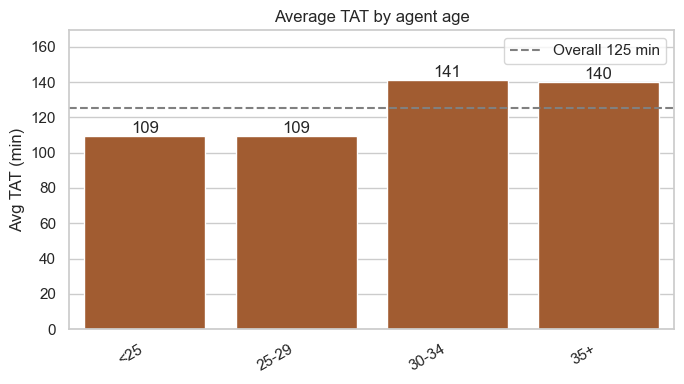

,AgeBand,orders,avg_tat,p90_tat,pct_late
0,<25,9905,109.3,175.0,16.8
1,25-29,9934,109.4,175.0,17.1
2,30-34,9967,141.1,210.0,39.1
3,35+,10215,140.0,210.0,38.9


In [69]:
tat_by("AgeBand", ["<25", "25-29", "30-34", "35+"], "Average TAT by agent age")

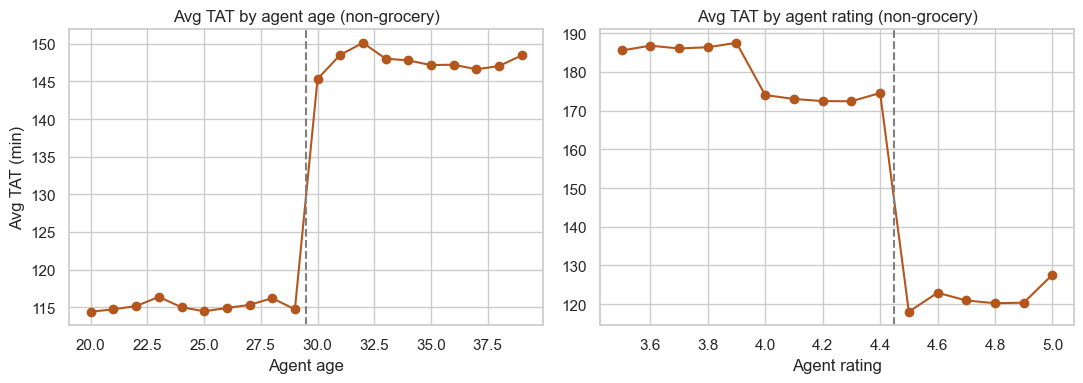

In [70]:
ng = df[df["Category"] != "Grocery"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
a = ng.groupby("Agent_Age")["Delivery_Time"].agg(["count", "mean"]); a = a[a["count"] >= 100]
axes[0].plot(a.index, a["mean"], marker="o", color=ACCENT); axes[0].axvline(29.5, ls="--", color="gray")
axes[0].set(title="Avg TAT by agent age (non-grocery)", xlabel="Agent age", ylabel="Avg TAT (min)")
r = ng.groupby(ng["Agent_Rating"].round(1))["Delivery_Time"].agg(["count", "mean"]); r = r[r["count"] >= 100]
axes[1].plot(r.index, r["mean"], marker="o", color=ACCENT); axes[1].axvline(4.45, ls="--", color="gray")
axes[1].set(title="Avg TAT by agent rating (non-grocery)", xlabel="Agent rating")
save("03b_age_rating_steps"); plt.show()

**Look closely:** TAT jumps by about 30 minutes at age 30, and falls in two steps as rating rises (at 4.0 and again at 4.5), with flat stretches in between. Real-world behaviour is rarely this clean, so these may be artefacts of how the data was produced. In a real company, check with the ops team before acting on them.

## 7. Statistical tests

In [71]:
rows = []
for c in ["Traffic", "Weather", "Area", "Vehicle", "Category"]:
    h, p = stats.kruskal(*[g["Delivery_Time"].values for _, g in df.groupby(c)])
    rows.append((c, "Kruskal-Wallis H", round(h, 1), p))
for c in ["distance_km", "Agent_Rating", "Agent_Age", "pickup_wait_min"]:
    d = df[[c, "Delivery_Time"]].dropna()
    r, p = stats.spearmanr(d[c], d["Delivery_Time"])
    rows.append((c, "Spearman rho", round(r, 2), p))
tests = pd.DataFrame(rows, columns=["variable", "test", "statistic", "p_value"])
tests["significant (p<0.05)"] = tests["p_value"] < 0.05
tests.assign(p_value=tests["p_value"].map("{:.2e}".format))

,variable,test,statistic,p_value,significant (p<0.05)
0,Traffic,Kruskal-Wallis H,5642.00,0.00e+00,True
1,Weather,Kruskal-Wallis H,2082.70,0.00e+00,True
2,Area,Kruskal-Wallis H,1705.90,0.00e+00,True
3,Vehicle,Kruskal-Wallis H,716.70,5.13e-155,True
4,Category,Kruskal-Wallis H,6910.70,0.00e+00,True
5,distance_km,Spearman rho,0.29,0.00e+00,True
6,Agent_Rating,Spearman rho,-0.26,0.00e+00,True
7,Agent_Age,Spearman rho,0.28,0.00e+00,True
8,pickup_wait_min,Spearman rho,-0.01,7.37e-02,False


Kruskal-Wallis checks whether TAT differs across groups; Spearman checks monotonic correlation. With tens of thousands of orders almost everything is "significant", so judge importance by effect size (minutes), which the next section quantifies.

## 8. How many minutes does each factor add? (NumPy regression)

In [72]:
def fit_ols(data, drop=()):
    X = pd.get_dummies(data.drop(columns=["Delivery_Time", *drop]), drop_first=True).astype(float)
    X.insert(0, "intercept", 1.0)
    y = data["Delivery_Time"].to_numpy()
    beta, *_ = np.linalg.lstsq(X.to_numpy(), y, rcond=None)
    pred = X.to_numpy() @ beta
    r2 = 1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum()
    return pd.Series(beta, index=X.columns).drop("intercept"), r2, len(y)

feat = df[["Delivery_Time", "distance_km", "Traffic", "Weather", "Area", "Vehicle"]].copy()
feat["age_30_plus"] = (df["Agent_Age"] >= 30).astype(float).where(df["Agent_Age"].notna())
feat["rating_below_4_5"] = (df["Agent_Rating"] < 4.5).astype(float).where(df["Agent_Rating"].notna())
feat["is_grocery"] = (df["Category"] == "Grocery").astype(float)
feat["Traffic"] = pd.Categorical(feat["Traffic"], categories=["Low", "Medium", "High", "Jam"])
feat["Weather"] = pd.Categorical(feat["Weather"], categories=["Sunny"] + sorted(w for w in feat["Weather"].unique() if w != "Sunny"))
feat = feat.dropna()

_, r2_base, _ = fit_ols(feat, drop=["age_30_plus", "rating_below_4_5", "is_grocery"])
coef, r2, n = fit_ols(feat)
coef = coef.sort_values(key=abs, ascending=False)
print(f"Base model (traffic, weather, area, vehicle, distance): R² = {r2_base:.2f}")
print(f"Extended model (+ agent age/rating flags, grocery): R² = {r2:.2f} on {n:,} orders")
coef.round(1).to_frame("minutes added vs baseline")

Base model (traffic, weather, area, vehicle, distance): R² = 0.26
Extended model (+ agent age/rating flags, grocery): R² = 0.65 on 39,958 orders


/var/folders/8s/b2jt_v9n3w33w2p74h42z43w0000gn/T/ipykernel_2666/917664838.py:6: RuntimeWarning: divide by zero encountered in matmul
  pred = X.to_numpy() @ beta
/var/folders/8s/b2jt_v9n3w33w2p74h42z43w0000gn/T/ipykernel_2666/917664838.py:6: RuntimeWarning: overflow encountered in matmul
  pred = X.to_numpy() @ beta
/var/folders/8s/b2jt_v9n3w33w2p74h42z43w0000gn/T/ipykernel_2666/917664838.py:6: RuntimeWarning: invalid value encountered in matmul
  pred = X.to_numpy() @ beta
/var/folders/8s/b2jt_v9n3w33w2p74h42z43w0000gn/T/ipykernel_2666/917664838.py:6: RuntimeWarning: divide by zero encountered in matmul
  pred = X.to_numpy() @ beta
/var/folders/8s/b2jt_v9n3w33w2p74h42z43w0000gn/T/ipykernel_2666/917664838.py:6: RuntimeWarning: overflow encountered in matmul
  pred = X.to_numpy() @ beta
/var/folders/8s/b2jt_v9n3w33w2p74h42z43w0000gn/T/ipykernel_2666/917664838.py:6: RuntimeWarning: invalid value encountered in matmul
  pred = X.to_numpy() @ beta


,minutes added vs baseline
is_grocery,-104.9
Area_Semi-Urban,68.6
rating_below_4_5,35.9
Traffic_Jam,34.9
Traffic_High,32.8
Weather_Fog,30.5
Weather_Cloudy,29.9
age_30_plus,25.0
Traffic_Medium,19.9
Weather_Windy,15.0


**How to read:** `distance_km` is minutes per extra km. Dummy variables are minutes versus the baseline group (traffic: Low, weather: Sunny, area and vehicle: the first alphabetical value, agent flags: age under 30 and rating 4.5 or above). The age and rating flags come from the EDA step charts, so they are chosen after looking at the data. This is association, not proof of cause, and R² tells you how much of the variation these factors explain.

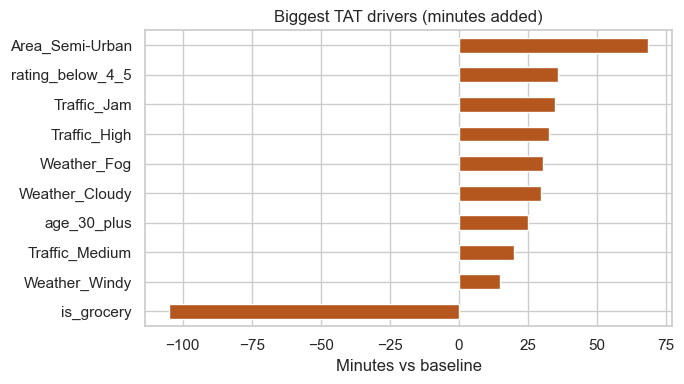

In [73]:
top = coef.head(10).sort_values()
plt.figure(figsize=(7, 4)); top.plot.barh(color=ACCENT)
plt.title("Biggest TAT drivers (minutes added)"); plt.xlabel("Minutes vs baseline"); save("04_drivers"); plt.show()

## 9. SQL view of the same data (CTEs and window functions)

In [74]:
con = sqlite3.connect(":memory:")
o = df[["Order_ID", "Order_Date", "week", "hour", "Area", "Traffic", "Weather", "Vehicle", "Category",
        "Delivery_Time", "distance_km"]].copy()
o["Order_Date"] = o["Order_Date"].dt.strftime("%Y-%m-%d"); o["week"] = o["week"].dt.strftime("%Y-%m-%d")
o.to_sql("orders", con, index=False)
q = lambda s: pd.read_sql(s, con)

# 9a. Slowest 3 categories inside each area
q("""
WITH seg AS (
  SELECT Area, Category, COUNT(*) AS orders, ROUND(AVG(Delivery_Time), 1) AS avg_tat
  FROM orders GROUP BY Area, Category HAVING COUNT(*) >= 50)
SELECT * FROM (
  SELECT *, RANK() OVER (PARTITION BY Area ORDER BY avg_tat DESC) AS slowest_rank FROM seg)
WHERE slowest_rank <= 3 ORDER BY Area, slowest_rank""")

,Area,Category,orders,avg_tat,slowest_rank
0,Metropolitan,Skincare,1885,137.8,1
1,Metropolitan,Snacks,1859,137.8,1
2,Metropolitan,Home,1840,137.6,3
3,Other,Kitchen,76,115.9,1
4,Other,Snacks,71,115.6,2
5,Other,Shoes,50,115.0,3
6,Urban,Cosmetics,557,119.3,1
7,Urban,Electronics,593,117.7,2
8,Urban,Kitchen,499,117.0,3


In [75]:
# 9b. Weekly TAT with week-over-week change (LAG)
q(f"""
WITH w AS (
  SELECT week, COUNT(*) AS orders, AVG(Delivery_Time) AS avg_tat, AVG(Delivery_Time > {SLA_MIN}) AS pct_late
  FROM orders GROUP BY week)
SELECT week, orders, ROUND(avg_tat, 1) AS avg_tat, ROUND(100 * pct_late, 1) AS pct_late,
       ROUND(100.0 * (avg_tat - LAG(avg_tat) OVER (ORDER BY week)) / LAG(avg_tat) OVER (ORDER BY week), 1) AS wow_change_pct
FROM w ORDER BY week""")

,week,orders,avg_tat,pct_late,wow_change_pct
0,2022-02-07,2151,121.9,25.1,NaN
1,2022-02-14,3480,129.6,31.6,6.3
2,2022-02-28,5773,124.0,27.3,-4.3
3,2022-03-07,6768,122.2,26.2,-1.5
4,2022-03-14,6631,128.5,30.4,5.2
5,2022-03-21,5738,124.3,28.0,-3.3
6,2022-03-28,6758,123.3,26.0,-0.8
7,2022-04-04,2747,128.9,31.7,4.6


In [76]:
# 9c. Where do the late orders come from? (share of all late orders by segment)
late_segments = q(f"""
WITH seg AS (
  SELECT Traffic, Area, COUNT(*) AS orders, SUM(Delivery_Time > {SLA_MIN}) AS late_orders
  FROM orders GROUP BY Traffic, Area HAVING COUNT(*) >= 100)
SELECT Traffic, Area, orders, late_orders,
       ROUND(100.0 * late_orders / orders, 1) AS pct_late,
       ROUND(100.0 * late_orders / SUM(late_orders) OVER (), 1) AS share_of_late_orders
FROM seg ORDER BY late_orders DESC LIMIT 8""")
late_segments

,Traffic,Area,orders,late_orders,pct_late,share_of_late_orders
0,Jam,Metropolitan,9896,4983,50.4,44.6
1,Medium,Metropolitan,7426,2515,33.9,22.5
2,High,Metropolitan,2995,1008,33.7,9.0
3,Low,Metropolitan,9634,871,9.0,7.8
4,Jam,Urban,2342,817,34.9,7.3
5,Medium,Urban,2088,413,19.8,3.7
6,High,Urban,833,185,22.2,1.7
7,Low,Urban,3597,146,4.1,1.3


**Key finding:** Jam traffic in Metropolitan areas is 24.7% of all orders but **44.6% of late orders** (50.4% of its orders run late). The top three segments (Jam, Medium and High traffic in Metropolitan areas) are 50.7% of orders but **76.1% of late orders**. Note the 9a ranking is not meaningful: categories differ by less than 1% inside each area.

## 10. Weekly KPI report and trend alerts (automation)

`kpi_report.py` automates the recurring report: it cleans the data, builds daily and weekly KPIs, flags days where average TAT jumps more than 2.5 standard deviations above the previous 7 days, lists the worst segments, and writes everything to Excel.

```
python kpi_report.py --data data/amazon_delivery.csv --sla 150
```

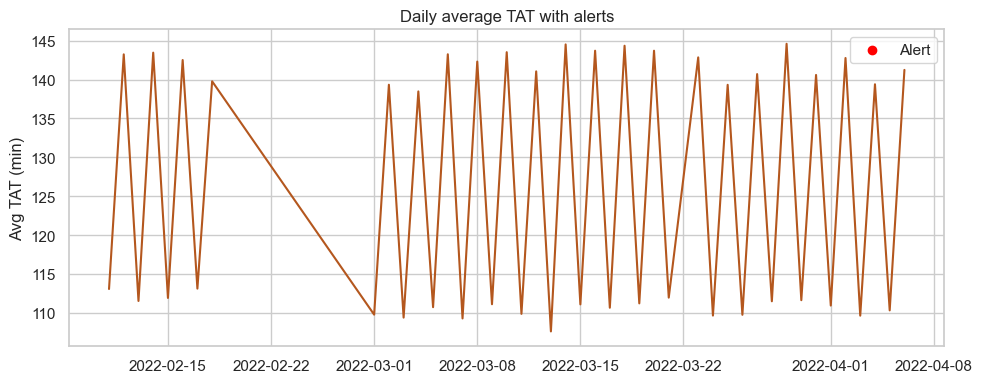

,Order_Date,orders,avg_tat,prior_mean,z_score


In [77]:
from kpi_report import kpis, flag_alerts
daily = flag_alerts(kpis(df, "Order_Date", SLA_MIN))
plt.figure(figsize=(10, 4)); plt.plot(daily["Order_Date"], daily["avg_tat"], color=ACCENT)
a = daily[daily["alert"]]; plt.scatter(a["Order_Date"], a["avg_tat"], color="red", zorder=3, label="Alert")
plt.title("Daily average TAT with alerts"); plt.ylabel("Avg TAT (min)"); plt.legend()
save("05_daily_alerts"); plt.show()
a[["Order_Date", "orders", "avg_tat", "prior_mean", "z_score"]]

**Result:** no alert days on this data. Weekly average TAT is stable between 122 and 130 min, and the weekly late rate stays between 25% and 32%. Note the 10-day gap (19 to 28 Feb) in the data. The alert logic is tested: on fake data with an injected slowdown it flagged the right day.

## 11. Streamlit dashboard

Run `streamlit run app.py` for the interactive dashboard (filters, KPIs, daily alerts, traffic and hour charts, worst segments, data-quality log).

## 12. Impact scenario (assumptions, not data)

The dataset has no cost fields, so the values below are **assumptions to be replaced with real finance numbers**. State them in the README.

In [78]:
LATE_ORDER_COST = 40    # assumed cost of one late order: refund, support contact, lost repeat (INR)
REDUCTION = 0.20        # assumed cut in late orders in the target segment

target = late_segments.iloc[0]
days = df["Order_Date"].nunique()
def saving(red, cost): return target["late_orders"] * red * cost
print(f"Target segment: {target['Traffic']} traffic, {target['Area']} area | "
      f"{int(target['late_orders']):,} late orders over {days} days")
print(f"Avoided late orders at {REDUCTION:.0%}: {target['late_orders'] * REDUCTION:,.0f}")
print(f"Estimated saving over the period: INR {saving(REDUCTION, LATE_ORDER_COST):,.0f} "
      f"(about INR {saving(REDUCTION, LATE_ORDER_COST) / days:,.0f} per day)")
pd.DataFrame({f"cost INR {c}": [saving(r, c) for r in [0.10, 0.20, 0.30]] for c in [20, 40, 60]},
             index=[f"reduction {int(r*100)}%" for r in [0.10, 0.20, 0.30]]).round(0)

Target segment: Jam traffic, Metropolitan area | 4,983 late orders over 44 days
Avoided late orders at 20%: 997
Estimated saving over the period: INR 39,864 (about INR 906 per day)


,cost INR 20,cost INR 40,cost INR 60
reduction 10%,9966.0,19932.0,29898.0
reduction 20%,19932.0,39864.0,59796.0
reduction 30%,29898.0,59796.0,89694.0


## 13. Summary and recommendations (fill in)

| # | Finding | Evidence | Recommendation | KPI to track |
|---|---|---|---|---|
| 1 | Grocery is delivered about 5x faster than every other category | 26.5 vs 131.5 min average at the same distance (9.6 vs 9.7 km); only 3.5% of grocery orders exceed 45 min | Find out why grocery is faster (store proximity, dispatch rules) and test the same model on other categories | Avg TAT and % over SLA by category |
| 2 | Jam traffic in Metropolitan areas drives most late orders | 24.7% of orders, 44.6% of late orders; 50.4% late vs 9.0% in Low traffic | Traffic-aware dispatch and realistic ETAs for jam conditions | % late in Jam × Metropolitan |
| 3 | 7 to 9 pm is the slowest window | About 147 min and 47% late vs 93 min in the morning | Add rider capacity for 7 to 9 pm | % late by hour |
| 4 | Lower-rated agents are much slower | Rating under 4.5: 165 to 190 min vs about 115 to 120 min (about +36 min in the model) | Coaching and routing for low-rated agents | Avg TAT by agent rating band |
| 5 | Semi-Urban deliveries are extremely slow | 239 min, 95% late, but only 138 orders | Check coverage and hub placement | Orders and TAT in Semi-Urban |

**Model:** traffic, weather, area, vehicle and distance explain only 26% of TAT variation. Adding agent age and rating flags and the grocery split lifts R² to 65%. Distance adds only about 1.8 min per km.

**Caution:** the step changes at agent age 30 and rating 4.5 are unusually clean and the average speed is only about 6 km/h, so this public dataset may be partly synthetic. Confirm with operations data before acting.

**Next steps:** feed live data into the weekly report, add city and store level cuts, and A/B test the top recommendation (a traffic-aware dispatch rule in the worst segment) against a control group.